# NumCompute Stream | Buffered decision tree demo

**COMP-5004, Assignment 2.2** — Reproducible test-then-train simulation, NumPy tree learning, per-chunk logging and matplotlib charts. **Run all cells from the top.** The CSV is part of this submission; the notebook reads it using our `CSVReader` (`numcompute_stream/io.py`), not pandas. The dataset is **synthetic** and contains missing values plus an intentionally drifting decision rule. Only NumPy, matplotlib, Python stdlib and package modules are imported.


In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / 'numcompute_stream').exists():
    ROOT = ROOT.parent
assert (ROOT / 'numcompute_stream').is_dir(), 'Open notebook in project folder or demo/ folder'
sys.path.insert(0, str(ROOT))

from numcompute_stream import DecisionTreeClassifier, Imputer, Pipeline, StreamTrainer
from numcompute_stream.io import CSVReader
from numcompute_stream.visualise import (plot_metric_over_time,
    compare_models, plot_predictions_vs_ground_truth)

CSV_PATH = ROOT / 'demo' / 'stream_data.csv'
OUTPUT = ROOT / 'demo' / 'figures'
OUTPUT.mkdir(exist_ok=True)
print('CSV:', CSV_PATH, 'exists:', CSV_PATH.exists())


CSV: C:\Users\Spoorthy R S\Downloads\COMP5004-Assignment2-NumCompute-assignment-2-2-stream\COMP5004-Assignment2-NumCompute-assignment-2-2-stream\demo\stream_data.csv exists: True


## 1. Read the data from CSV in chunks

There are four numeric features and a binary label (0 or 1). The empty feature cells represent NaNs; we update the imputer on each chunk. Streaming order is preserved—there is no random train/test reshuffle that would leak future samples.


In [2]:
reader = CSVReader(CSV_PATH, target='label')
X_all, y_all = reader.read()
CHUNK_SIZE = 30
chunks = list(reader.read_chunked(CHUNK_SIZE))
print('Full shape:', X_all.shape, y_all.shape)
print('Chunks:', len(chunks), 'first chunk:', chunks[0][0].shape)
print('Missing feature cells:', int(np.isnan(X_all).sum()))
print('Class counts:', np.unique(y_all, return_counts=True))


Full shape: (1200, 4) (1200,)
Chunks: 40 first chunk: (30, 4)
Missing feature cells: 183
Class counts: (array([0, 1]), array([636, 564]))


## 2. Streaming pipeline with buffered tree

For each incoming chunk, `fit_chunk` first **scores using the last fitted model**, then updates the preprocessing and buffers the chunk for training. A tree is retrained only when its pending samples reach the chosen buffer size. Before the first tree is available, the chunk accuracy is NaN by design and is not included in cumulative accuracy.


In [3]:
def make_trainer(buffer_size):
    pipeline = Pipeline([
        ('imputer', Imputer()),
        ('tree', DecisionTreeClassifier(max_depth=5, min_samples_split=6,
                                       buffer_size=buffer_size, criterion='gini', random_state=23))
    ])
    return StreamTrainer(pipeline, rolling_window=120)

small = make_trainer(buffer_size=60)
large = make_trainer(buffer_size=240)

for X_chunk, y_chunk in chunks:
    small.fit_chunk(X_chunk, y_chunk)
    large.fit_chunk(X_chunk, y_chunk)

for label, trainer in [('Small buffer', small), ('Large buffer', large)]:
    print(label, '| cumulative prequential accuracy:', round(trainer.accuracy.result(), 4),
          '| retrains:', trainer.pipeline.model.retrain_count_,
          '| tree:', trainer.pipeline.model.summary())
print('First three logs:', small.logs[:3])


Small buffer | cumulative prequential accuracy: 0.8193 | retrains: 20 | tree: {'nodes': 13, 'leaves': 7, 'depth': 4}
Large buffer | cumulative prequential accuracy: 0.7958 | retrains: 5 | tree: {'nodes': 29, 'leaves': 15, 'depth': 5}
First three logs: [{'chunk': 1, 'samples_seen': 30, 'chunk_size': 30, 'chunk_accuracy': nan, 'cumulative_accuracy': nan, 'rolling_accuracy': nan, 'train_seconds': 0.00028609996661543846, 'retrained': False, 'buffered_samples': 30, 'retrain_count': 0, 'memory_bytes': 1200}, {'chunk': 2, 'samples_seen': 60, 'chunk_size': 30, 'chunk_accuracy': nan, 'cumulative_accuracy': nan, 'rolling_accuracy': nan, 'train_seconds': 0.007156399893574417, 'retrained': True, 'buffered_samples': 0, 'retrain_count': 1, 'memory_bytes': 240}, {'chunk': 3, 'samples_seen': 90, 'chunk_size': 30, 'chunk_accuracy': 0.8333333333333334, 'cumulative_accuracy': 0.8333333333333334, 'rolling_accuracy': 0.8333333333333334, 'train_seconds': 9.250000584870577e-05, 'retrained': False, 'buffered_

## 3. Accuracy changes as chunks arrive

The plot has an intentional gap during warm-up. A lower buffer can refresh more often, whereas a larger buffer retrains less frequently and may take longer per update. **Results are empirical, not guaranteed.**


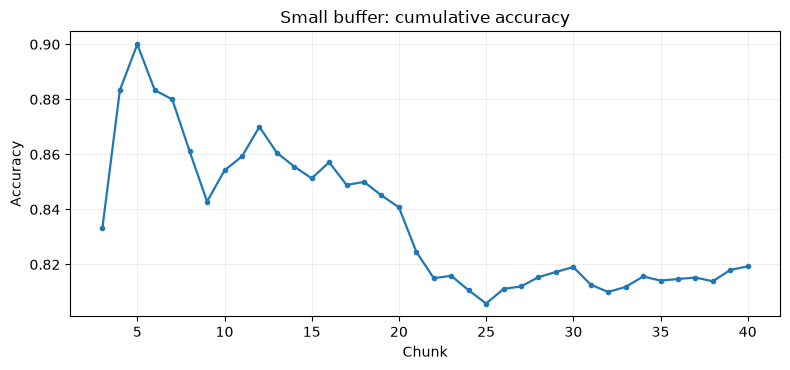

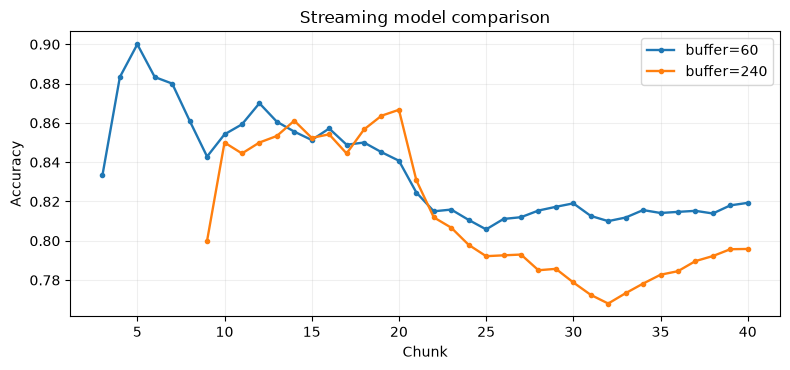

In [4]:
small_acc = [item['cumulative_accuracy'] for item in small.logs]
large_acc = [item['cumulative_accuracy'] for item in large.logs]
fig = plot_metric_over_time(small_acc, title='Small buffer: cumulative accuracy',
                            ylabel='Accuracy', save_path=OUTPUT / 'accuracy_over_time.png')
plt.show()
fig = compare_models(small_acc, large_acc, labels=('buffer=60','buffer=240'),
                     save_path=OUTPUT / 'model_comparison.png')
plt.show()


## 4. Model adaptation, buffer sizes and memory

`retrained` is True exactly at a buffer threshold. Memory numbers approximate NumPy array storage for the tree node counts and the pending chunks; they are **not** the full Python process resident memory. `train_seconds` includes any actual retrain or lightweight buffer append.


In [5]:
for label,trainer in [('Small',small),('Large',large)]:
    logs=trainer.logs
    times=[row['train_seconds'] for row in logs if row['retrained']]
    print(label, 'retrain count:',len(times),
          'mean retrain (ms):',round(1000*np.mean(times),2),
          'max recorded model memory (bytes):',max(r['memory_bytes'] for r in logs))
    print('retrain chunks:',[r['chunk'] for r in logs if r['retrained']])


Small retrain count: 20 mean retrain (ms): 7.44 max recorded model memory (bytes): 1472
retrain chunks: [2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26, 28, 30, 32, 34, 36, 38, 40]
Large retrain count: 5 mean retrain (ms): 18.89 max recorded model memory (bytes): 8992
retrain chunks: [8, 16, 24, 32, 40]


## 5. Predictions and ground truth for a held-out view

For an illustrative final prediction chart, take the **last chunk** and compare labels with current tree predictions. Note that this is **not** a prequential evaluation of that last chunk, because it has already been used in training. For unbiased online accuracy, use the earlier test-then-train log values instead.


Last chunk predictions: [1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0]
Last chunk ground truth: [1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1]


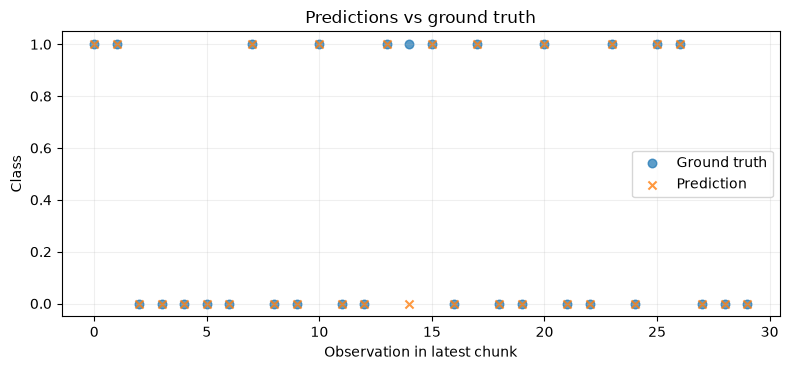

In [6]:
X_latest,y_latest = chunks[-1]
latest_predictions = small.pipeline.predict(X_latest)
print('Last chunk predictions:',latest_predictions[:15].tolist())
print('Last chunk ground truth:',y_latest[:15].tolist())
fig = plot_predictions_vs_ground_truth(y_latest,latest_predictions,
                                       save_path=OUTPUT / 'last_chunk_predictions.png')
plt.show()


## 6. Verification / discussion

- The buffered model is **not** a Hoeffding tree: it is an ordinary, from-scratch greedy decision tree periodically retrained on the latest buffered chunks.
- First samples have no scored model; plot gaps show that cold start rather than fabricating an accuracy.
- NaNs are imputed with updated feature means and the tree also supports direct NaN split routing.
- Class ties resolve to the smallest class; split candidates resolve by smaller feature, threshold and missing-left option.
- A separate benchmark script (`py benchmark/run_stream_benchmarks.py`) compares Python loops with NumPy and the actual impact of buffer size.
- Run `python -m unittest discover -s tests -v` at the terminal to reproduce the unit-test evidence. In the report, explain why changing buffers affects adaptation, cost and warm-up.
